In [40]:
#ANALISIS EXPLORATORIO DE DATOS (EDA)
#Proceso de exploracion y comprension inicial de dataset.
#Descubrir errores, detectar patrones

#importar librerias
import pandas as pd # carga de datos
import numpy as np #analisis de datos
import matplotlib.pyplot as plt #Graficas

#Cargar dataset
df = pd.read_csv('titanic.csv') #cargar dataset (DataFrame)
print("carga de archivos exitosa")

df.head(10) #muestra las primeras 10 filas del dataset}
df.info() #informacion del dataset
df.describe() #estadisticas descriptivas del dataset






carga de archivos exitosa
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
#Limpieza de datos
# Corrección: Asignar directamente el resultado a la columna
# Limpieza de datos
df['Age'] = df['Age'].fillna(df['Age'].median()) # Rellenar valores faltantes con la mediana
df = df.dropna(subset=['Embarked']) # Eliminar filas con valores faltantes en la columna 'Embarked'

# errors='ignore' evita el KeyError si la celda se ejecuta más de una vez
df = df.drop(columns=['Cabin'], errors='ignore')

df['Pclass'] = df['Pclass'].astype('category') #

df.info()



<class 'pandas.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  889 non-null    int64   
 1   Survived     889 non-null    int64   
 2   Pclass       889 non-null    category
 3   Name         889 non-null    str     
 4   Sex          889 non-null    str     
 5   Age          889 non-null    float64 
 6   SibSp        889 non-null    int64   
 7   Parch        889 non-null    int64   
 8   Ticket       889 non-null    str     
 9   Fare         889 non-null    float64 
 10  Embarked     889 non-null    str     
dtypes: category(1), float64(2), int64(4), str(4)
memory usage: 111.9 KB


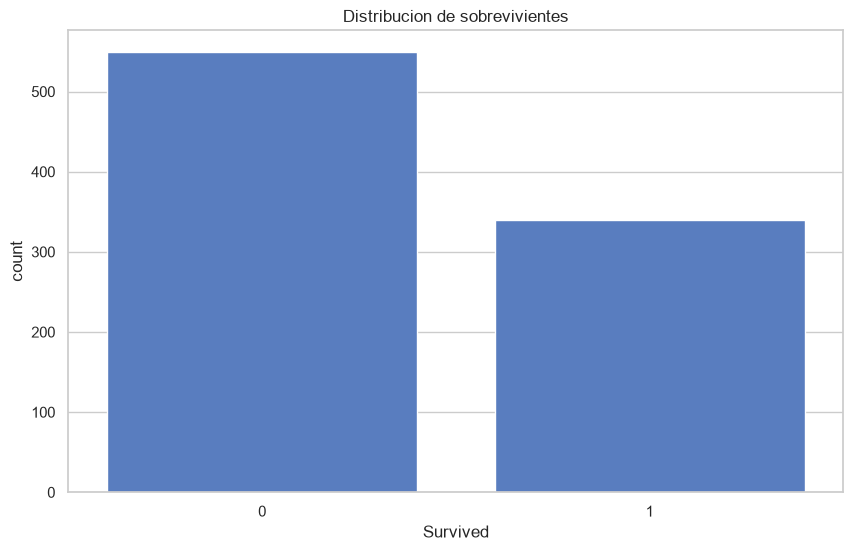

In [ ]:
#Configuracion estetica de las graficas
import seaborn as sns
sns.set(style="whitegrid", palette="muted") #Configuracion estetica de las graficas
plt.rcParams["figure.figsize"]=(10,6) #Tamano de las graficas

#Variable objetivo
sns.countplot(x="Survived", data=df)
plt.title("Distribucion de sobrevivientes")
plt.show() # Mostrar la grafica

In [ ]:
#VARIABLES CATEGORICAS
cat_vars = ["Sex", "Pclass", "Embarked"] #Se crean una lista con las variables categoricas


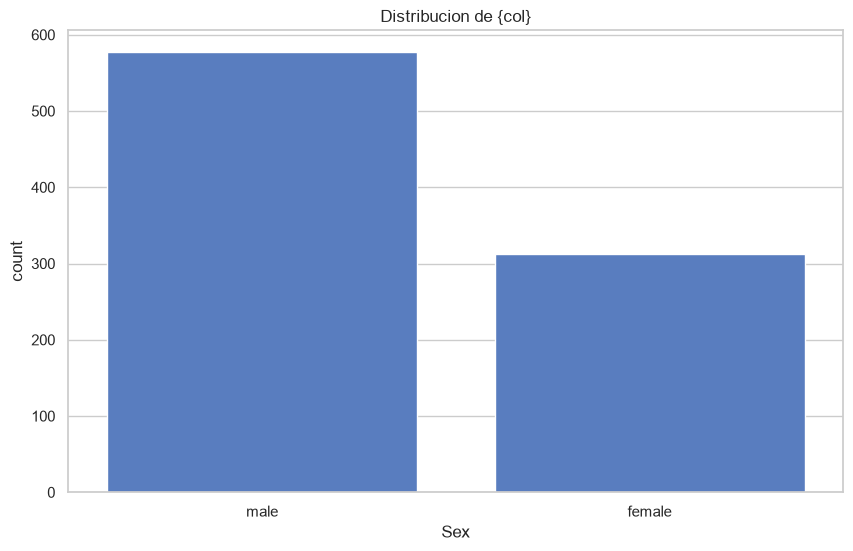

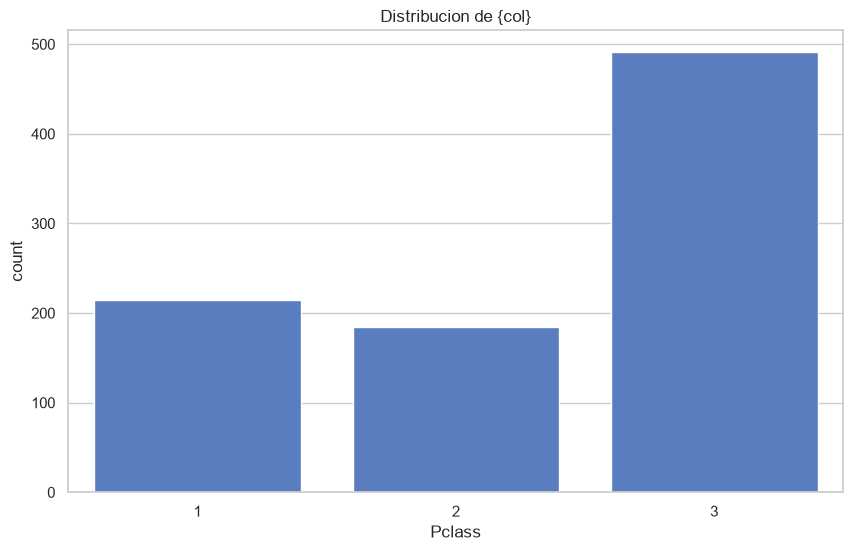

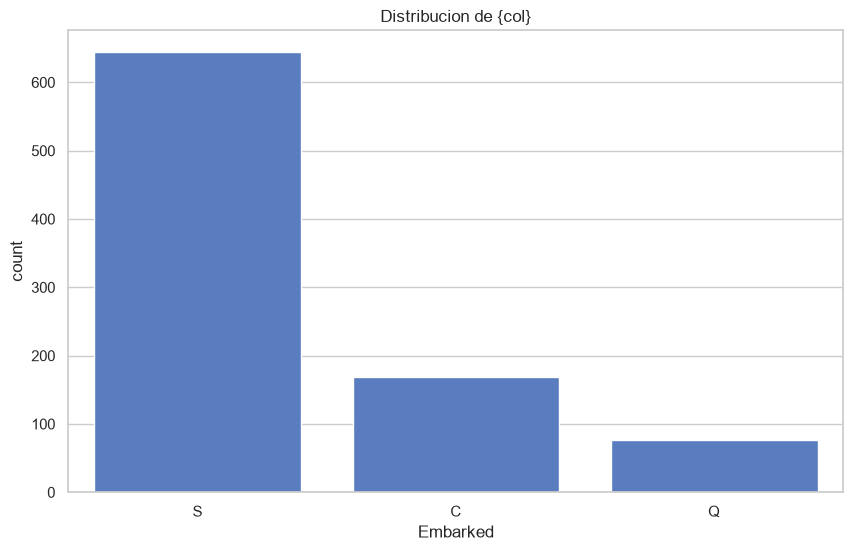

In [45]:
for col in cat_vars:
    sns.countplot(x=col, data=df)
    plt.title("Distribucion de {col}")
    plt.show()

In [46]:
#Variables numericas
num_vars = ["Age", "Fare"]

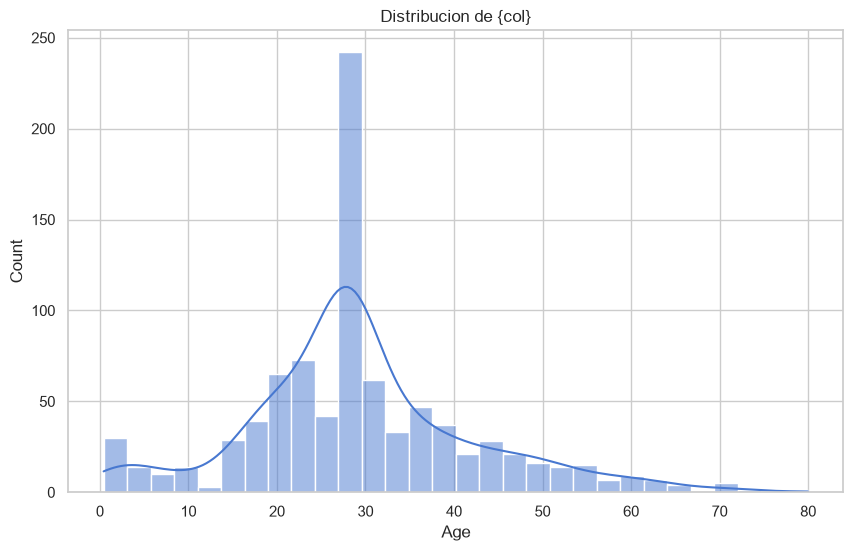

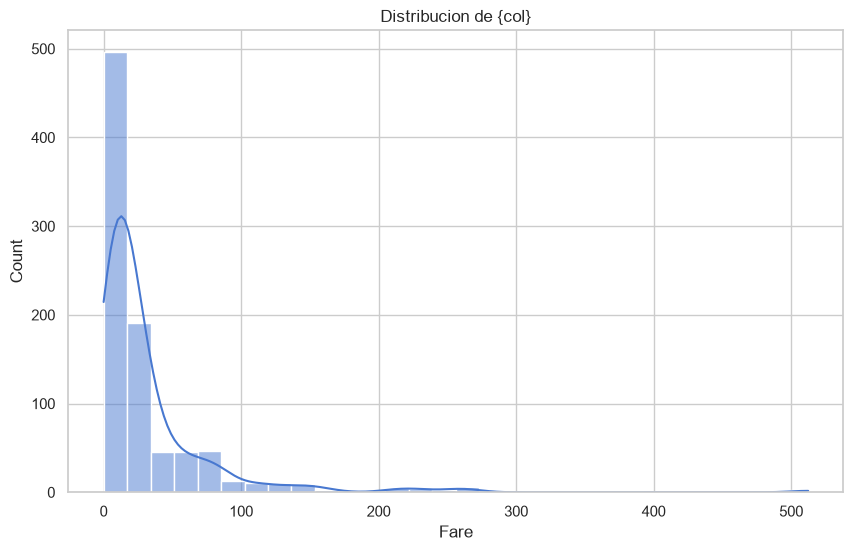

In [49]:
for col in num_vars:
    sns.histplot(df[col].dropna(), kde=True, bins = 30)
    plt.title("Distribucion de {col}")
    plt.show()

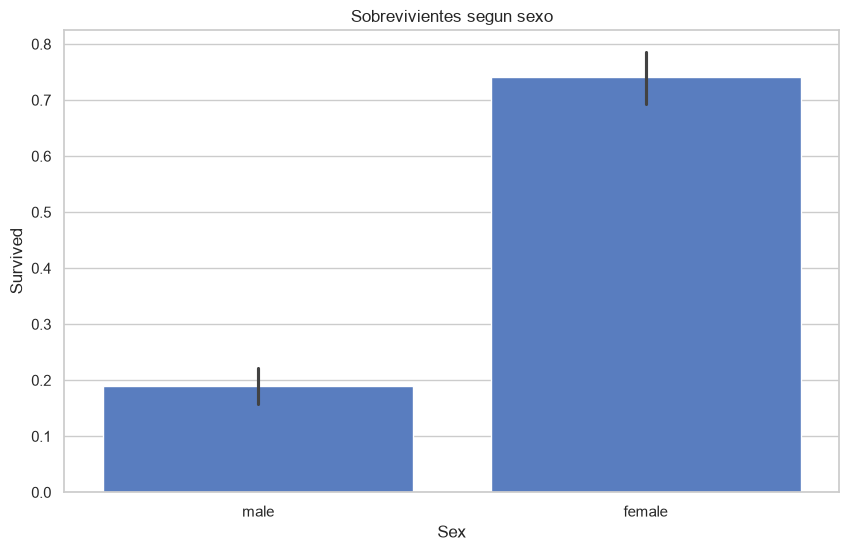

In [50]:
#Analisis Bivariante (Dos Variables)
#Supervivencia por sexo

sns.barplot(x="Sex", y="Survived", data=df)
plt.title("Sobrevivientes segun sexo")
plt.show()

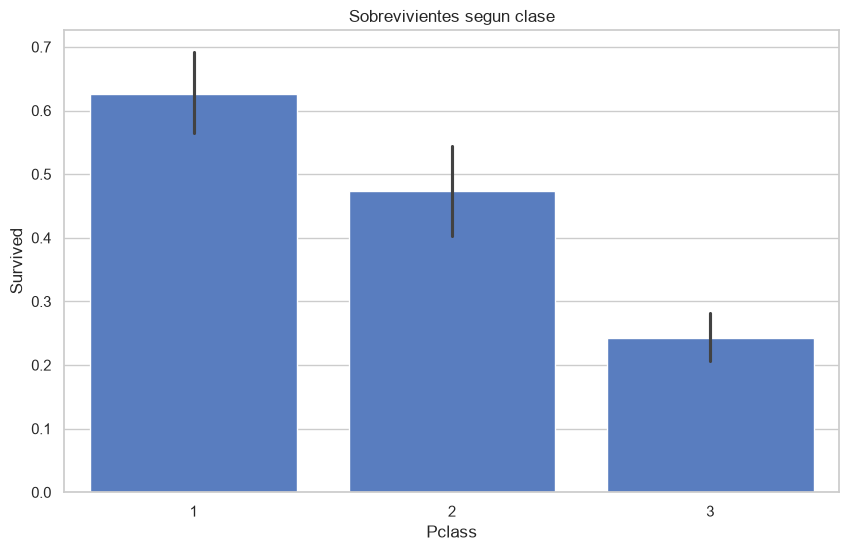

In [51]:
#Supervivencia por clase
sns.barplot(x="Pclass", y="Survived", data=df)
plt.title("Sobrevivientes segun clase")
plt.show()

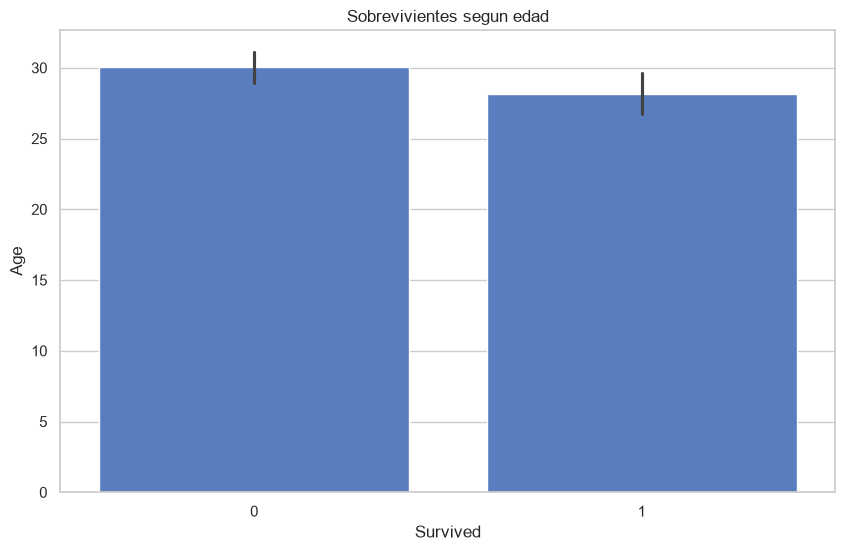

In [52]:
#Supervivencia por sexo
sns.barplot(x="Survived", y="Age", data=df)
plt.title("Sobrevivientes segun edad")
plt.show()

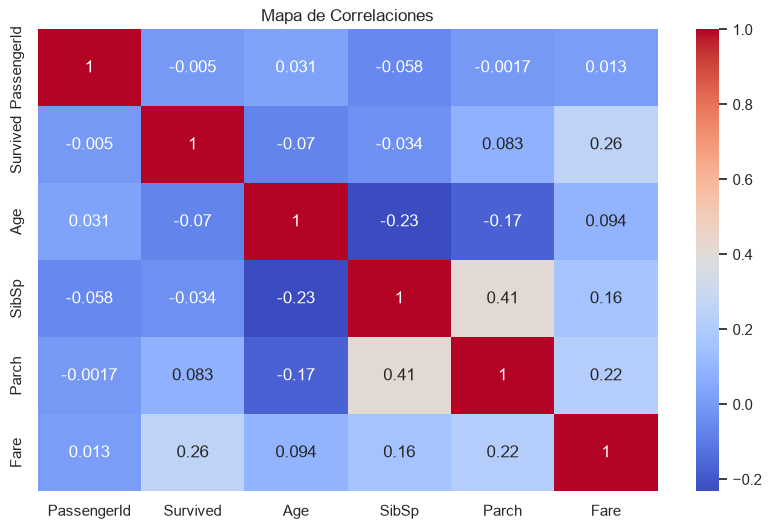

In [ ]:
#Mapa de correlaciones
corr = df.corr(numeric_only=True) # Calcula la matriz de correlación para las variables numéricas del DataFrame
sns.heatmap(corr, annot=True, cmap="coolwarm") # Configuracion de matriz confusion
plt.title("Mapa de Correlaciones")
plt.show()

In [55]:
#Guardar el dataset nuevo limpio
df.to_csv('datos_nuevos_titanic.csv', index=False)
